# 02 · Calidad de datos, triangulación de fuentes y censura

**Objetivo.** Auditar las instantáneas del notebook 01 en cinco dimensiones (completitud, validez, consistencia, unicidad, oportunidad), triangular nuestros indicadores contra fuentes externas y documentar la censura y los sesgos que condicionan los análisis posteriores.

**Punto del enunciado:** 6 (reporte de calidad de datos). **Hipótesis:** HF5 (los ratios calculados desde EDGAR son consistentes con fuentes independientes dentro de una tolerancia razonable).

**Entradas (instantáneas en `data/snapshots`):** `precios_semanales`, `precios_mensuales`, `edgar_hechos`, `ratios_anuales`, `info_yf`, `damodaran_pe`, `damodaran_roc`, `damodaran_ev_ebitda`, `damodaran_margenes`.
**Salidas:** figura `completitud_edgar.png` (en `entregables/entrega_1/assets`) y la matriz de decisiones de calidad (sección 7). Ninguna instantánea se modifica: las decisiones de limpieza se aplican aguas abajo.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json
from asistente import config, datos, edgar, fundamentales as fu, damodaran as dm, indicadores as ind
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
config.DIR_ASSETS.mkdir(parents=True, exist_ok=True)
sem = datos.cargar_snapshot("precios_semanales")
print(sem.shape, sem.ticker.nunique(), sem.fecha.min().date(), sem.fecha.max().date())

(31038, 4) 34 2009-01-05 2026-10-12


## 1. Auditoría de precios semanales por dimensión de calidad

| Dimensión | Verificación sobre precios | Columna de la tabla |
|---|---|---|
| Completitud | semanas observadas vs. esperadas en el rango de cada ticker | `semanas`, `inicio`, `fin` |
| Validez | cierres nulos o no positivos; volumen nulo | `nulos_close`, `close_no_positivo`, `volumen_nulo` |
| Consistencia | saltos de retorno logarítmico > 5σ; fechas siempre lunes | `saltos_5sd`, `lunes` |
| Unicidad | pares (fecha, ticker) repetidos | `duplicados` |
| Oportunidad | última barra frente a la fecha de descarga | sección 1.3 |

In [2]:
r = sem.sort_values(["ticker", "fecha"]).groupby("ticker").close.transform(lambda c: np.log(c).diff())
sem = sem.sort_values(["ticker", "fecha"]).assign(r=r)
audit = sem.groupby("ticker").agg(
    inicio=("fecha", "min"), fin=("fecha", "max"), semanas=("fecha", "count"),
    nulos_close=("close", lambda s: s.isna().sum()), close_no_positivo=("close", lambda s: (s <= 0).sum()),
    volumen_cero=("volume", lambda s: (s == 0).sum()), volumen_nulo=("volume", lambda s: s.isna().sum()),
    saltos_5sd=("r", lambda s: (np.abs(s - s.mean()) > 5 * s.std()).sum()))
audit["duplicados"] = sem.duplicated(["fecha", "ticker"]).groupby(sem.ticker).sum()
audit["lunes"] = sem.groupby("ticker").fecha.apply(lambda s: (s.dt.dayofweek == 0).all())
audit

,inicio,fin,semanas,nulos_close,close_no_positivo,volumen_cero,volumen_nulo,saltos_5sd,duplicados,lunes
ticker,,,,,,,,,,
AAPL,2009-01-05,2026-10-12,928,0,0,0,0,1,0,True
ADBE,2009-01-05,2026-10-12,928,0,0,0,0,1,0,True
BAC,2009-01-05,2026-10-12,928,0,0,0,0,4,0,True
C,2009-01-05,2026-10-12,928,0,0,0,0,5,0,True
CL,2009-01-05,2026-10-12,928,0,0,0,0,1,0,True
COST,2009-01-05,2026-10-12,928,0,0,0,0,1,0,True
CRM,2009-01-05,2026-10-12,928,0,0,0,0,1,0,True
CSCO,2009-01-05,2026-10-12,928,0,0,0,0,2,0,True
GIS,2009-01-05,2026-10-12,928,0,0,0,0,1,0,True


In [3]:
cols = ["nulos_close", "close_no_positivo", "volumen_cero", "volumen_nulo", "saltos_5sd", "duplicados"]
prob = audit[(audit[cols] > 0).any(axis=1)]
print("tickers (incl. benchmark/ETF) en la tabla:", len(audit), "| con algún problema:", len(prob))
print(prob[cols].to_string())
esperadas = pd.Series(pd.date_range(sem.fecha.min(), sem.fecha.max(), freq="W-MON"))
print("semanas esperadas:", len(esperadas), "| semanas distintas observadas:", sem.fecha.nunique())
print("semanas faltantes por ticker (sobre su rango propio):")
print((((audit.fin - audit.inicio).dt.days // 7 + 1) - audit.semanas).loc[lambda s: s != 0].to_string())

tickers (incl. benchmark/ETF) en la tabla: 34 | con algún problema: 32
        nulos_close  close_no_positivo  volumen_cero  volumen_nulo  saltos_5sd  duplicados
ticker                                                                                    
AAPL              0                  0             0             0           1           0
ADBE              0                  0             0             0           1           0
BAC               0                  0             0             0           4           0
C                 0                  0             0             0           5           0
CL                0                  0             0             0           1           0
COST              0                  0             0             0           1           0
CRM               0                  0             0             0           1           0
CSCO              0                  0             0             0           2           0
GIS               0

In [4]:
meta = json.load(open(config.DIR_SNAPSHOTS / "precios_semanales.meta.json"))
print("Instantánea descargada:", meta["fecha_descarga"])
print("Última semana por ticker:", sem.groupby("ticker").fecha.max().unique()[:3])
ult = sem[sem.fecha == sem.fecha.max()]
print("Volumen de la última semana / mediana propia (mediana entre tickers):",
      round((ult.volume / sem.groupby("ticker").volume.transform("median").loc[ult.index]).median(), 3))
print("Mín. volumen relativo por semana (todas) y fecha:")
vr = sem.assign(vr=sem.volume / sem.groupby("ticker").volume.transform("median")).nsmallest(5, "vr")[["ticker", "fecha", "volume", "vr"]]
print(vr.to_string(index=False))

Instantánea descargada: 2026-10-14T05:18:07+00:00
Última semana por ticker: <DatetimeArray>
['2026-10-12 00:00:00']
Length: 1, dtype: datetime64[ms]
Volumen de la última semana / mediana propia (mediana entre tickers): 0.546
Mín. volumen relativo por semana (todas) y fecha:
ticker      fecha         volume     vr
  NVDA 2026-10-12 238208611.0000 0.1148
  AAPL 2026-10-12 103745365.0000 0.1562
   SPY 2026-10-12  70297660.0000 0.1583
  AAPL 2025-12-22 105646200.0000 0.1590
  AAPL 2025-12-29 110986500.0000 0.1671


**Lectura (tabla de auditoría y conteo).** No hay nulos, cierres no positivos, volumen nulo, duplicados ni semanas faltantes en ningún ticker; las 928 semanas esperadas coinciden con las observadas y todas las fechas son lunes. Las únicas dos anomalías estructurales son de cobertura: META (753 semanas desde 2012-05-14) y KHC (589 semanas desde 2015-07-06). El único indicador activo es `saltos_5sd`: 32 de 34 series (30 acciones, SPY y 3 ETF de sector) tienen al menos un salto, y solo NVDA y PG tienen cero. Los saltos se examinan en la sección 2; los 3 ETF y SPY se auditan solo como referencia.

**Oportunidad.** La última barra es la del lunes 2026-10-12 y la instantánea se descargó el 2026-10-14: es una semana en curso (incompleta). Su volumen es en mediana 0.546 de la mediana propia y las 3 barras de menor volumen relativo de toda la muestra son de esa semana (NVDA 0.115, AAPL 0.156, SPY 0.158). Un volumen bajo en una barra parcial no es "falta de negociación".

**Justificación:** la última semana se **marca como parcial** y se excluye de etiquetas y de evaluación (su retorno futuro no está completo); se conserva en la instantánea porque sirve como precio más reciente para los múltiplos de la sección 4.

In [5]:
mu_sd = sem.groupby("ticker").r.agg(["mean", "std"])
sem = sem.join(mu_sd, on="ticker")
sem["z"] = (sem.r - sem["mean"]) / sem["std"]
saltos = sem[sem.z.abs() > 5][["ticker", "fecha", "r", "z", "volume"]].sort_values("fecha")
saltos["vol_rel"] = saltos.volume / sem.groupby("ticker").volume.transform("median").loc[saltos.index]
print("Filas con volume == 0:", int((sem.volume == 0).sum()))
print("Saltos > 5 sigma:", len(saltos))
print(saltos.to_string(index=False))

Filas con volume == 0: 0
Saltos > 5 sigma: 73
ticker      fecha       r        z          volume  vol_rel
   BAC 2009-01-12 -0.5929 -10.0727 1579398100.0000   4.6309
   XLF 2009-01-12 -0.1775  -5.2984 1211486557.0000   4.6509
     C 2009-01-12 -0.6568 -10.3803  214255150.0000   2.2730
   WFC 2009-01-12 -0.2970  -5.8556  546567900.0000   5.4203
   USB 2009-02-09 -0.2667  -5.7310  180400700.0000   4.6326
   WFC 2009-02-16 -0.3678  -7.2431  815021900.0000   8.0826
   BAC 2009-02-16 -0.3850  -6.5523 1852894300.0000   5.4328
   JPM 2009-02-16 -0.2157  -5.0942  376737400.0000   5.2623
     C 2009-02-16 -0.5821  -9.2014  122770630.0000   1.3025
   XLF 2009-02-16 -0.1735  -5.1822 1304210771.0000   5.0069
   USB 2009-02-23  0.3020   6.4179  294951400.0000   7.5743
   WFC 2009-03-02 -0.3403  -6.7038 1087572700.0000  10.7855
   XLF 2009-03-02 -0.2068  -6.1633 1362194318.0000   5.2294
   USB 2009-03-02 -0.4839 -10.3718  308334900.0000   7.9180
   JPM 2009-03-02 -0.3607  -8.4704  634548400.0000   8

## 2. Significado de los ceros y de los saltos (T2)

Un valor extremo o un cero no se interpreta sin evidencia. Dos preguntas: (i) ¿hay `volume == 0`? y (ii) ¿qué son los saltos > 5σ: errores de dato (split mal ajustado, feriado) o movimientos reales de mercado?

In [6]:
def episodio(f):
    if pd.Timestamp("2009-01-01") <= f <= pd.Timestamp("2009-05-31"): return "crisis financiera 2008-09"
    if pd.Timestamp("2020-02-17") <= f <= pd.Timestamp("2020-04-10"): return "COVID-19 (feb-abr 2020)"
    return "idiosincrático / otro"
saltos["episodio"] = saltos.fecha.map(episodio)
print(saltos.groupby("episodio").agg(n=("r", "size"), tickers=("ticker", "nunique"), vol_rel_med=("vol_rel", "median")).to_string())
print("Saltos con volumen > mediana propia:", int((saltos.vol_rel > 1).sum()), "de", len(saltos))
print("\nSaltos idiosincráticos:")
print(saltos[saltos.episodio == "idiosincrático / otro"][["ticker", "fecha", "r"]].to_string(index=False))
nv = sem[(sem.ticker == "NVDA") & sem.fecha.between("2024-05-27", "2024-06-24")][["fecha", "close", "r", "z"]]
print("\nNVDA alrededor del split 10:1 (10-jun-2024):"); print(nv.to_string(index=False))
print("NVDA: máx |z| de toda la serie:", round(sem[sem.ticker == "NVDA"].z.abs().max(), 2))
print("KHC: primera fecha", sem[sem.ticker == "KHC"].fecha.min().date(), "| primer r:", sem[sem.ticker == "KHC"].r.iloc[0])
sem["salto"] = sem.z.abs() > 5
sem["parcial"] = sem.fecha == sem.fecha.max()
print("\nBanderas creadas: salto =", int(sem.salto.sum()), "| parcial =", int(sem.parcial.sum()))

                            n  tickers  vol_rel_med
episodio                                           
COVID-19 (feb-abr 2020)    19       13       2.4627
crisis financiera 2008-09  33       10       5.8476
idiosincrático / otro      21       15       3.3893
Saltos con volumen > mediana propia: 73 de 73

Saltos idiosincráticos:
ticker      fecha       r
  CSCO 2010-11-08 -0.1856
  META 2013-07-22  0.2732
 GOOGL 2015-07-13  0.2296
   GIS 2018-03-19 -0.1328
   KHC 2019-02-18 -0.3093
   KHC 2019-08-05 -0.1951
   CRM 2020-08-24  0.2672
   WMT 2022-05-16 -0.2167
  COST 2022-05-16 -0.1774
  ADBE 2022-09-12 -0.2762
  META 2022-10-24 -0.2705
  SCHW 2023-03-06 -0.2767
   TFC 2023-03-13 -0.2398
  INTC 2024-07-29 -0.3781
  ORCL 2025-06-09  0.2125
  ORCL 2025-09-08  0.2272
   KMB 2025-11-03 -0.1421
  ORCL 2026-04-13  0.2372
  CSCO 2026-05-11  0.2022
  ORCL 2026-06-22 -0.2157
  MSFT 2026-07-27  0.1968

NVDA alrededor del split 10:1 (10-jun-2024):
     fecha    close       r       z
2024-05-27 109.

**Lectura (ceros y saltos).** Hay 0 filas con `volume == 0`, de modo que no existe un "cero" que interpretar. Los 73 saltos > 5σ tienen volumen superior a la mediana propia en 73 de 73 casos (mediana del volumen relativo entre 2.5 y 5.8 según episodio), lo que es incompatible con un error de dato y compatible con movimientos reales. Se concentran en: crisis financiera de 2009 (33 saltos en 10 tickers, casi todos bancos y XLF), COVID-19 febrero-abril 2020 (19 saltos en 13 tickers) y 21 idiosincráticos en 15 tickers. Las causas de los idiosincráticos son hipótesis coherentes con el calendario de resultados y eventos (p. ej. KHC 2019-02-18 con -31% en la semana del deterioro de activos de febrero de 2019; WMT y COST en la semana del 2022-05-16, de resultados del primer trimestre; META 2022-10-24 de resultados), **no verificadas con una fuente externa** para los eventos de 2025-2026. NVDA no muestra artefacto de split: su semana del 2024-06-10 tiene retorno 0.0871 (z = 1.32) y su máximo |z| es 4.25, así que los precios están ajustados por splits. KHC no tiene retorno previo al 2015-07-06: su serie arranca con la fusión Kraft-Heinz y no hay historial empalmado.

**Justificación:** los 73 saltos se **mantienen sin modificar**: son movimientos reales con volumen elevado, y eliminarlos o winsorizarlos borraría exactamente las colas que el módulo de riesgo debe medir (curtosis, drawdown). Solo se **marcan** (columna `salto`) para que las etiquetas y la simulación puedan hacer pruebas de sensibilidad sin ellos. No se imputa ningún valor porque no hay nulos.

## 3. Completitud de EDGAR (concepto × ticker)

Se mide, por concepto XBRL y ticker, la fracción de años fiscales 2009-2025 con dato en `ratios_anuales`. Un 0 % significa que el concepto **no se reporta con la etiqueta us-gaap elegida**, no que el valor sea cero (T2).

In [7]:
rat = datos.cargar_snapshot("ratios_anuales")
hechos = datos.cargar_snapshot("edgar_hechos")
conceptos = list(edgar.CONCEPTOS)
rat09 = rat[(rat.end.dt.year >= 2009) & (rat.end.dt.year <= 2025)]
print("Filas ratios_anuales 2009-2025:", len(rat09), "| años por ticker (mín-mediana-máx):",
      rat09.groupby("ticker").size().agg(["min", "median", "max"]).tolist())
comp = rat09.groupby("ticker")[conceptos].apply(lambda d: d.notna().mean()).T
orden = [t for g in config.UNIVERSO.values() for t in g]; comp = comp[orden]
print("Tickers con utilidad_bruta > 0%:", int((comp.loc["utilidad_bruta"] > 0).sum()), "/ 30")
print("Tickers con capex > 0%:", int((comp.loc["capex"] > 0).sum()), "/ 30")
print("Completitud media por concepto:"); print(comp.mean(axis=1).sort_values().round(3).to_string())
print("Duplicados exactos en edgar_hechos:", int(hechos.duplicated().sum()))

Filas ratios_anuales 2009-2025: 510 | años por ticker (mín-mediana-máx): [14.0, 17.0, 19.0]
Tickers con utilidad_bruta > 0%: 14 / 30
Tickers con capex > 0%: 22 / 30
Completitud media por concepto:
utilidad_bruta       0.4230
utilidad_operativa   0.6500
capex                0.6500
deuda_lp             0.7200
caja                 0.7880
ingresos             0.8060
cfo                  0.8880
acciones             0.9600
utilidad_neta        0.9820
patrimonio           0.9960
Duplicados exactos en edgar_hechos: 33


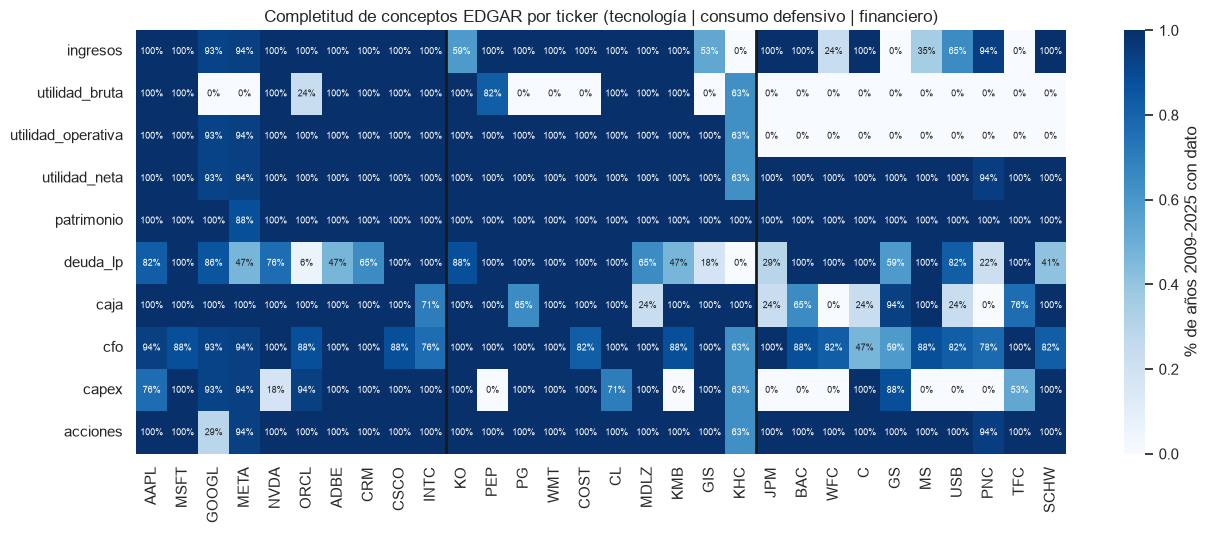

In [8]:
fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(comp, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, annot_kws={"size": 6.5}, cbar_kws={"label": "% de años 2009-2025 con dato"}, ax=ax)
for x in (10, 20): ax.axvline(x, color="k", lw=2)
ax.set_title("Completitud de conceptos EDGAR por ticker (tecnología | consumo defensivo | financiero)"); ax.set_xlabel(""); ax.set_ylabel("")
fig.savefig(config.DIR_ASSETS / "completitud_edgar.png", dpi=150, bbox_inches="tight"); plt.show()

In [9]:
por_ind = pd.DataFrame({i: comp[t].mean(axis=1) for i, t in config.UNIVERSO.items()})
print(por_ind.loc[["utilidad_bruta", "capex", "ingresos", "utilidad_neta", "patrimonio", "deuda_lp", "cfo"]].round(3).to_string())
print("Tickers con utilidad_bruta<50%:", [t for t in orden if comp.loc["utilidad_bruta", t] < 0.5])
print("Tickers con capex<50%:", [t for t in orden if comp.loc["capex", t] < 0.5])
print("Celdas con 0%:", int((comp == 0).sum().sum()), "de", comp.size)
for c in ["ingresos", "utilidad_neta", "utilidad_operativa"]:
    print(c, "< 70%:", {t: round(comp.loc[c, t], 2) for t in orden if comp.loc[c, t] < 0.7})
print("Tickers con utilidad_bruta == 0%:", [t for t in orden if comp.loc["utilidad_bruta", t] == 0])

                tecnologia  consumo_defensivo  financiero
utilidad_bruta      0.7240             0.5460      0.0000
capex               0.8750             0.7340      0.3410
ingresos            0.9870             0.8120      0.6180
utilidad_neta       0.9870             0.9630      0.9940
patrimonio          0.9880             1.0000      1.0000
deuda_lp            0.7090             0.7180      0.7340
cfo                 0.9220             0.9340      0.8070
Tickers con utilidad_bruta<50%: ['GOOGL', 'META', 'ORCL', 'PG', 'WMT', 'COST', 'GIS', 'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'USB', 'PNC', 'TFC', 'SCHW']
Tickers con capex<50%: ['NVDA', 'PEP', 'KMB', 'JPM', 'BAC', 'WFC', 'MS', 'USB', 'PNC']
Celdas con 0%: 40 de 300
ingresos < 70%: {'KO': np.float64(0.59), 'GIS': np.float64(0.53), 'KHC': np.float64(0.0), 'WFC': np.float64(0.24), 'GS': np.float64(0.0), 'MS': np.float64(0.35), 'USB': np.float64(0.65), 'TFC': np.float64(0.0)}
utilidad_neta < 70%: {'KHC': np.float64(0.63)}
utilidad_oper

**Lectura (heatmap).** Entre los 30 emisores, `utilidad_bruta` tiene dato en solo 14 (completitud media 42.3 %) y `capex` en 22 (65.0 %). Por sector, la utilidad bruta es 72.4 % en tecnología, 54.6 % en consumo defensivo y 0.0 % en financieras; el capex es 87.5 %, 73.4 % y 34.1 %. Las 10 financieras tienen además 0 % en `utilidad_operativa`, de modo que ROIC y márgenes operativos no existen para ellas, y `ingresos` falla en 8 tickers (p. ej. KHC, GS y TFC en 0 %, WFC en 24 %). `patrimonio` es el concepto más completo (99.6 %) y `utilidad_neta` el segundo (98.2 %; tras incorporar `ProfitLoss` como etiqueta alternativa, PNC y TFC ya tienen dato y el mínimo es KHC con 63 %). Un 0 en la figura es ausencia de la etiqueta us-gaap elegida: GOOGL, META, PG, WMT, COST y GIS (no financieras) tampoco reportan `GrossProfit` y GOOGL tiene `acciones` en solo 29 %.

**Justificación:** (i) para las financieras se usa un **set de ratios propio** (ROE, P/B, margen neto, relación patrimonio-activos cuando exista) porque margen bruto, margen operativo, capex/ventas y ROIC no son calculables ni conceptualmente comparables en un banco (el "ingreso" y el "costo de ventas" no tienen el mismo significado); esto cumple la decisión de la spec 4.4 con evidencia. (ii) Para no financieras, los ratios basados en un concepto ausente quedan en NaN y **no se imputan** (un 0 no es "sin utilidad bruta"): cada indicador compuesto se calcula solo donde sus insumos existen. (iii) Los 33 duplicados exactos de `edgar_hechos` (reportes repetidos) se eliminan en `tabla_anual` al elegir un valor por `end`; no cambian ninguna cifra anual.

**Síntesis (sección 3).**
- Hay **16 de 30** emisores sin utilidad bruta (10 financieras y 6 no financieras) y solo 22 con capex: ningún modelo puede depender de esos dos conceptos.
- Los conceptos núcleo (patrimonio, utilidad neta) cubren 99.6 % y 98.2 %: ROE y P/B son los ratios más robustos; P/E depende de `acciones` y falla en GOOGL.
- Decisión: set de ratios separado para financieras y NaN explícito, sin imputación.

## 4. Triangulación de fuentes (HF5)

Tres comparaciones: (a) P/E y ROE propios (último precio y último 10-K publicado, sin look-ahead) frente a `trailingPE` y `returnOnEquity` de yfinance; (b) medianas de industria propias frente a Damodaran; (c) verificación de utilidad neta y patrimonio frente al 10-K de AAPL, KO y JPM (criterio ±5 %).

In [10]:
info = datos.cargar_snapshot("info_yf").set_index("ticker")
filas = []
for t in orden:
    rt = rat[rat.ticker == t].sort_values("filed").dropna(subset=["filed"])
    p = sem[(sem.ticker == t)].sort_values("fecha").iloc[-1]
    ult = rt[rt.filed <= p.fecha].iloc[-1]
    filas.append(dict(ticker=t, fin_fiscal=ult.end.date(), filed=ult.filed.date(), close=p.close,
                      eps_propio=ult.eps, pe_propio=p.close / ult.eps if ult.eps > 0 else np.nan, roe_propio=ult.roe))
tri = pd.DataFrame(filas).set_index("ticker").join(info[["trailingPE", "returnOnEquity"]])
tri["dif_pe"] = tri.pe_propio / tri.trailingPE - 1
tri["dif_roe"] = tri.roe_propio / tri.returnOnEquity - 1
tri

,fin_fiscal,filed,close,eps_propio,pe_propio,roe_propio,trailingPE,returnOnEquity,dif_pe,dif_roe
ticker,,,,,,,,,,
AAPL,2025-09-27,2025-10-31,341.2700,7.4650,45.7160,1.5191,39.0916,1.4875,0.1695,0.0213
MSFT,2026-06-30,2026-07-29,543.4500,17.9457,30.2831,0.3023,30.2758,0.3404,0.0002,-0.1118
GOOGL,2025-12-31,2026-02-05,353.7800,10.8070,32.7361,0.3183,17.6978,0.4868,0.8497,-0.3461
META,2025-12-31,2026-01-29,762.5000,23.4880,32.4634,0.2783,27.9919,0.2985,0.1597,-0.0676
NVDA,2026-01-25,2026-02-25,228.5200,4.8979,46.6568,0.7633,28.8900,1.1721,0.6150,-0.3488
ORCL,2026-05-31,2026-06-22,143.2000,5.8638,24.4212,0.4020,22.4451,0.4119,0.0880,-0.0242
ADBE,2025-11-28,2026-01-15,236.2800,16.6979,14.1503,0.6134,13.2966,0.6190,0.0642,-0.0090
CRM,2026-01-31,2026-03-02,238.0100,7.8002,30.5133,0.1261,22.2232,0.1938,0.3730,-0.3494
CSCO,2026-07-25,2026-09-02,115.0700,3.3276,34.5808,0.2638,34.6596,0.2732,-0.0023,-0.0342


In [11]:
for c, nom in [("dif_pe", "P/E"), ("dif_roe", "ROE")]:
    d = tri[c].dropna()
    print(f"{nom}: n comparables={len(d)} | mediana dif. relativa={d.median():+.3f} | mediana |dif|={d.abs().median():.3f} | casos |dif|>20%={int((d.abs() > 0.2).sum())}")
print("trailingPE nulos en info_yf:", int(tri.trailingPE.isna().sum()), tri.index[tri.trailingPE.isna()].tolist())
print("pe_propio nulo (EPS<=0 o sin acciones):", tri.index[tri.pe_propio.isna()].tolist())
print("Meses desde el cierre fiscal hasta la fecha de precio (mediana):",
      round(((sem.fecha.max() - pd.to_datetime(tri.fin_fiscal)).dt.days / 30.4).median(), 1))
print("Mayores |dif| P/E:"); print(tri.dif_pe.abs().sort_values(ascending=False).head(8).round(3).to_string())
print("Mayores |dif| ROE:"); print(tri.dif_roe.abs().sort_values(ascending=False).head(8).round(3).to_string())
print("ROE: correlación de Spearman propio vs yf:", round(tri[["roe_propio", "returnOnEquity"]].corr("spearman").iloc[0, 1], 3))
print("P/E: correlación de Spearman propio vs yf:", round(tri[["pe_propio", "trailingPE"]].corr("spearman").iloc[0, 1], 3))

P/E: n comparables=27 | mediana dif. relativa=+0.088 | mediana |dif|=0.096 | casos |dif|>20%=5
ROE: n comparables=30 | mediana dif. relativa=-0.097 | mediana |dif|=0.113 | casos |dif|>20%=11
trailingPE nulos en info_yf: 3 ['INTC', 'GIS', 'KHC']
pe_propio nulo (EPS<=0 o sin acciones): ['INTC', 'GIS', 'KHC']
Meses desde el cierre fiscal hasta la fecha de precio (mediana): 9.4
Mayores |dif| P/E:
ticker
GOOGL   0.8500
NVDA    0.6150
MDLZ    0.4400
CRM     0.3730
PEP     0.3250
GS      0.1950
AAPL    0.1690
KMB     0.1670
Mayores |dif| ROE:
ticker
CL      13.7670
INTC     0.9780
GIS      0.8870
KHC      0.6020
CRM      0.3490
NVDA     0.3490
GOOGL    0.3460
MDLZ     0.2890
ROE: correlación de Spearman propio vs yf: 0.986
P/E: correlación de Spearman propio vs yf: 0.929


**Lectura (propio vs. yfinance).** Con 27 emisores comparables en P/E (INTC, GIS y KHC quedan fuera: EPS negativo y `trailingPE` nulo), la diferencia relativa mediana es +0.088 (mediana de la diferencia absoluta 0.096) y 5 casos superan 20 % (GOOGL +0.850, NVDA +0.615, MDLZ +0.440, CRM +0.373, PEP +0.325). En ROE hay 30 comparables, mediana -0.097 (|dif| mediana 0.113) y 11 casos > 20 %; la correlación de Spearman es 0.986 para ROE y 0.929 para P/E. Los casos extremos de ROE (CL +13.767, INTC -0.978, GIS -0.887, KHC +0.602) corresponden a patrimonio cercano a cero o utilidad cercana a cero, donde la razón es inestable.

**Explicación de las diferencias.** (i) *Desfase temporal*: nuestro EPS es el del último año fiscal publicado (mediana de 9.4 meses desde su cierre hasta la fecha del precio), mientras que yfinance usa utilidades de los últimos 12 meses (TTM); en empresas en crecimiento (NVDA, GOOGL, CRM) la utilidad TTM es mayor, de modo que su P/E es menor que el nuestro (signo positivo de `dif_pe`). (ii) *Utilidad diluida y ajustes*: nuestro EPS es `utilidad_neta / acciones diluidas promedio`; yfinance puede usar EPS ajustado o por clase de acción (GOOGL), y para GOOGL el concepto de acciones solo está en 29 % de los años. (iii) *Definición de ROE*: no hemos verificado si yfinance usa patrimonio promedio o final; nuestro ROE usa patrimonio final del año, lo que es compatible con la diferencia mediana de -0.097 (hipótesis no probada aquí).

In [12]:
dpe, droc, dmar = (datos.cargar_snapshot(n) for n in ["damodaran_pe", "damodaran_roc", "damodaran_margenes"])
ult_rat = rat.sort_values("filed").groupby("ticker").tail(1).set_index("ticker")
tri["margen_neto"] = ult_rat.margen_neto; tri["roic"] = ult_rat.roic
tri["industria"] = [config.industria_de(t) for t in tri.index]
filas = []
for ramo in config.UNIVERSO:
    g = tri[tri.industria == ramo]
    fe, fr, fm = (dm.filas_industria(x, ramo) for x in (dpe, droc, dmar))
    filas.append(dict(industria=ramo, pe_propio=g.pe_propio.median(), pe_yf=g.trailingPE.median(),
                      dam_current_pe=fe.current_pe.median(), dam_trailing_pe=fe.trailing_pe.median(),
                      mn_propio=g.margen_neto.median(), mn_dam=fm.net_margin.median(),
                      roic_propio=g.roic.median() if ramo != "financiero" else np.nan,
                      roic_dam=fr.unadjusted_after_tax_roic.median(), n_pe_propio=g.pe_propio.notna().sum()))
ind_cmp = pd.DataFrame(filas).set_index("industria")
ind_cmp["razon_pe_propio_vs_dam_trailing"] = ind_cmp.pe_propio / ind_cmp.dam_trailing_pe
ind_cmp

,pe_propio,pe_yf,dam_current_pe,dam_trailing_pe,mn_propio,mn_dam,roic_propio,roic_dam,n_pe_propio,razon_pe_propio_vs_dam_trailing
industria,,,,,,,,,,
tecnologia,32.4634,27.9919,122.4918,81.1320,0.2846,0.1778,0.2656,0.5362,9,0.4001
consumo_defensivo,31.1104,25.1064,37.1134,47.7638,0.1046,0.0561,0.1854,0.2506,8,0.6513
financiero,14.8722,13.2071,26.8139,33.6015,0.2863,0.2749,NaN,NaN,10,0.4426


**Lectura (propio vs. Damodaran).** Con 9, 8 y 10 emisores con P/E propio, las medianas propias son 32.463 (tecnología), 31.110 (consumo defensivo) y 14.872 (financiero) frente a un P/E de Damodaran (`trailing_pe`, mediana de las industrias mapeadas) de 81.132, 47.764 y 33.602; la razón propio/Damodaran es 0.400, 0.651 y 0.443. El orden entre sectores coincide en ambas fuentes (tecnología > consumo defensivo > financiero con `current_pe`: 122.492, 37.113, 26.814). El margen neto propio es 0.285, 0.105 y 0.286 frente a 0.178, 0.056 y 0.275 de Damodaran, y el ROIC propio (tecnología 0.266, consumo 0.185) queda por debajo del ROIC después de impuestos de Damodaran (0.536 y 0.251).

**Explicación.** Damodaran agrega **todas las empresas listadas en EE. UU. de cada industria** (p. ej. 568 bancos regionales, 309 de software), incluidas pequeñas y con pérdidas, mientras que nuestros pares son 10 empresas grandes por sector; las diferencias de nivel son estructurales y no un error de cálculo.

**Justificación de la fuente por uso:** (i) **EDGAR propio** para todo ratio por emisor y para las medianas de industria usadas en los modelos, porque es la única fuente con fecha de publicación (`filed`) y permite evitar look-ahead; (ii) **yfinance** solo como control puntual (TTM actual, sin historia); (iii) **Damodaran** únicamente como referencia de *orden relativo* entre industrias y como contexto en el reporte, no como nivel de comparación del universo de 30, ni como insumo de las etiquetas.

In [13]:
ev = datos.cargar_snapshot("damodaran_ev_ebitda")
print("Columnas:", list(ev.columns))
# Encabezado de grupos leído de vebitda.xls (hoja 'Industry Averages', fila previa al encabezado; actualizado 2026-01-05):
print("Fila de grupos del xls: columnas 3-6 = 'Only positive EBITDA firms'; columnas 7-10 = 'All firms'")
print("Mediana de EV/EBITDA, solo EBITDA positivo (ev_ebitda):", round(ev.ev_ebitda.median(), 2), "| todas las empresas (ev_ebitda_2):", round(ev.ev_ebitda_2.median(), 2))
print("Filas con ev_ebitda_2 < ev_ebitda:", int((ev.ev_ebitda_2 < ev.ev_ebitda).sum()), "de", len(ev))

Columnas: ['industry_name', 'number_of_firms', 'ev_ebitdar_d', 'ev_ebitda', 'ev_ebit', 'ev_ebit_1_t', 'ev_ebitdar_d_2', 'ev_ebitda_2', 'ev_ebit_2', 'ev_ebit_1_t_2']
Fila de grupos del xls: columnas 3-6 = 'Only positive EBITDA firms'; columnas 7-10 = 'All firms'
Mediana de EV/EBITDA, solo EBITDA positivo (ev_ebitda): 13.36 | todas las empresas (ev_ebitda_2): 15.13
Filas con ev_ebitda_2 < ev_ebitda: 12 de 96


**Nota sobre `damodaran_ev_ebitda` (columnas `_2`).** El snapshot repite las columnas EV/EBITDAR&D, EV/EBITDA, EV/EBIT y EV/EBIT(1-t); `leer_tabla` sufija con `_2` la segunda aparición. Se pudo determinar abriendo el encabezado de `vebitda.xls` (hoja "Industry Averages", actualizada 2026-01-05; descargado el 2026-10-14 desde `pages.stern.nyu.edu/~adamodar/pc/datasets/vebitda.xls`): la fila de grupos rotula las columnas del primer bloque como **"Only positive EBITDA firms"** y las del segundo como **"All firms"**. Por tanto `ev_ebitda` = solo empresas con EBITDA positivo y `ev_ebitda_2` = todas las empresas. La salida de arriba es coherente con esa lectura (mediana 13.36 para `ev_ebitda` vs. 15.13 para `ev_ebitda_2`; `ev_ebitda_2` es mayor en 84 de 96 industrias, plausible si las empresas con EBITDA bajo o negativo elevan el múltiplo agregado), pero no la prueba; la rotulación de las columnas es la evidencia principal. **Decisión:** si se usa EV/EBITDA como contexto, se usa `ev_ebitda` (solo EBITDA positivo), porque el múltiplo con EBITDA negativo carece de sentido económico; los `_2` no se usan.

In [14]:
# Cifras leídas a mano del 10-K publicado (millones de USD), ver URLs en la celda markdown siguiente
k10 = {"AAPL": (112_010, 73_733), "KO": (13_107, 32_169), "JPM": (57_048, 362_438)}
filas = []
for t, (ni, eq) in k10.items():
    u = ult_rat.loc[t]
    filas.append(dict(ticker=t, fin_fiscal=u.end.date(), ni_propio=u.utilidad_neta / 1e6, ni_10k=ni,
                      pat_propio=u.patrimonio / 1e6, pat_10k=eq))
ver = pd.DataFrame(filas).set_index("ticker")
ver["dif_ni"] = ver.ni_propio / ver.ni_10k - 1; ver["dif_pat"] = ver.pat_propio / ver.pat_10k - 1
ver["dentro_5pct"] = (ver[["dif_ni", "dif_pat"]].abs() < 0.05).all(axis=1)
ver

,fin_fiscal,ni_propio,ni_10k,pat_propio,pat_10k,dif_ni,dif_pat,dentro_5pct
ticker,,,,,,,,
AAPL,2025-09-27,112010.0000,112010,73733.0000,73733,0.0000,0.0000,True
KO,2025-12-31,13107.0000,13107,32169.0000,32169,0.0000,0.0000,True
JPM,2025-12-31,57048.0000,57048,362438.0000,362438,0.0000,0.0000,True


**Fuentes de la verificación contra el 10-K** (cifras en millones de USD, leídas de la presentación en EDGAR; las fechas de publicación coinciden con el `filed` de nuestra tabla):
- AAPL, 10-K FY2025 (filed 2025-10-31): https://www.sec.gov/Archives/edgar/data/320193/000032019325000079/aapl-20250927.htm — utilidad neta 112,010; patrimonio total 73,733.
- KO, 10-K FY2025 (filed 2026-02-20): https://www.sec.gov/Archives/edgar/data/21344/000162828026010047/0001628280-26-010047-index.htm — utilidad neta atribuible 13,107 (estado de resultados, R3); patrimonio atribuible a los accionistas 32,169 (balance, R5).
- JPM, 10-K FY2025 (filed 2026-02-13): https://www.sec.gov/Archives/edgar/data/19617/000162828026008131/0001628280-26-008131-index.htm — utilidad neta 57,048 (R4); patrimonio total 362,438 (balance, R5).

**Lectura (verificación contra el 10-K).** Para AAPL, KO y JPM la utilidad neta y el patrimonio de nuestra tabla coinciden con el 10-K publicado con diferencia relativa 0.0000 en los seis valores (112,010 / 73,733; 13,107 / 32,169; 57,048 / 362,438 millones), por debajo del criterio de ±5 %. Esto es esperable: nuestra tabla es el mismo hecho XBRL que alimenta el 10-K, de modo que la prueba confirma la **extracción y la elección de etiqueta** (`NetIncomeLoss`, `StockholdersEquity`), no la veracidad contable del reporte. Los cierres fiscales y fechas `filed` también coinciden con las presentaciones de EDGAR.

**Justificación:** HF5 se **acepta con matices**: el cálculo propio reproduce exactamente el 10-K en los 3 emisores verificados y se aproxima a yfinance (mediana |dif| 0.096 en P/E y 0.113 en ROE), con discrepancias explicadas por periodicidad (anual vs. TTM) y no por errores de extracción. La verificación cubre 3 de 30 emisores, así que no se extrapola a los demás.

**Síntesis (sección 4).**
- Propio vs. 10-K: 6 de 6 cifras con diferencia 0.0000; propio vs. yfinance: 5 casos de P/E y 11 de ROE por encima de 20 %, concentrados en crecimiento (GOOGL, NVDA, CRM) y en patrimonio o utilidad cercanos a cero (CL, INTC, GIS, KHC).
- Propio vs. Damodaran: mismo orden entre sectores, niveles 0.400-0.651 veces los de Damodaran por diferencia de universo.
- Decisión: EDGAR como fuente principal con `filed`; yfinance como control TTM; Damodaran solo como referencia relativa. PNC y TFC ya tienen P/E propio tras añadir `ProfitLoss` como etiqueta alternativa de utilidad neta; solo GOOGL queda sin P/E (acciones en 29 % de los años).

## 5. Identidad e industria de los tickers (E1)

Se compara nuestra asignación sectorial (10 emisores por sector, definida en `config.UNIVERSO`) con `sector` e `industry` de yfinance. Una discrepancia no implica error: son taxonomías distintas (GICS-like de Yahoo frente a un criterio de comportamiento económico).

In [15]:
ident = info[["sector", "industry"]].copy()
ident["nuestra_industria"] = [config.industria_de(t) for t in ident.index]
ident = ident.loc[orden]
print(pd.crosstab(ident.nuestra_industria, ident.sector).to_string())
print()
print(ident[ident.groupby("nuestra_industria").sector.transform(lambda s: s != s.mode().iloc[0])].to_string())
print("\nIndustrias de Yahoo por sector nuestro (n distintas):", ident.groupby("nuestra_industria").industry.nunique().to_dict())
print("\nDetalle minoristas y brokers:"); print(ident.loc[["WMT", "COST", "SCHW", "GS", "MS"]].to_string())

sector             Communication Services  Consumer Defensive  Financial Services  Technology
nuestra_industria                                                                            
consumo_defensivo                       0                  10                   0           0
financiero                              0                   0                  10           0
tecnologia                              2                   0                   0           8

                        sector                        industry nuestra_industria
ticker                                                                          
GOOGL   Communication Services  Internet Content & Information        tecnologia
META    Communication Services  Internet Content & Information        tecnologia

Industrias de Yahoo por sector nuestro (n distintas): {'consumo_defensivo': 5, 'financiero': 3, 'tecnologia': 6}

Detalle minoristas y brokers:
                    sector         industry  nuestra_industr

**Lectura (identidad e industria).** Nuestra asignación coincide con el sector de yfinance en 28 de 30 emisores: los 10 de consumo defensivo son "Consumer Defensive" y los 10 financieros son "Financial Services". Las dos discrepancias están en tecnología: GOOGL y META figuran como "Communication Services" (industria "Internet Content & Information"). Dentro de cada sector yfinance distingue 6 industrias en tecnología, 5 en consumo defensivo y 3 en financiero, así que "10 pares" mezcla negocios distintos. WMT y COST son "Discount Stores" (minoristas) dentro de "Consumer Defensive", y SCHW, GS y MS son todos "Capital Markets" frente a JPM y los demás bancos.

**Justificación:** se **mantiene nuestra asignación** porque el criterio del proyecto es comportamiento económico comparable (ciclicidad, apalancamiento y múltiplos) y GOOGL y META comparten con tecnología el motor de ingresos publicitarios y la exposición a crecimiento; la discrepancia se documenta. Para las comparaciones con Damodaran se usa el mapeo de `damodaran.MAPA_INDUSTRIAS`, que ya separa software, hardware y semiconductores, y los casos discutibles (WMT, COST, SCHW, GS, MS) se leen con cautela al comparar con la mediana sectorial, no se reasignan.

**Síntesis (sección 5).**
- 28 de 30 coinciden con yfinance; GOOGL y META son los dos casos de sector distinto.
- Decisión: sin reasignaciones; las medianas sectoriales son de 10 pares heterogéneos y se acompañan de dispersión en los notebooks posteriores.

## 6. Censura y sesgos (T3)

Una observación está **censurada** cuando no se puede calcular su etiqueta (retorno futuro a N semanas, aún no ocurrido) o su indicador (ventana de calentamiento insuficiente). Censurar no es eliminar un error: son datos que todavía no existen y no deben imputarse ni tratarse como "sin movimiento".

In [16]:
precio = sem.pivot(index="fecha", columns="ticker", values="close")[orden]
total = precio.notna().sum().sum()
cens = pd.DataFrame({N: [int(precio.shift(-N).isna().sum().sum() - precio.isna().sum().sum()), ] for N in (4, 12, 26)}, index=["obs_censuradas"]).T
cens["pct_del_total"] = cens.obs_censuradas / total
cens["tickers_afectados"] = 30
print("Observaciones de las 30 acciones:", int(total)); print(cens.to_string())
sma50 = precio.apply(lambda c: ind.dist_media(c.dropna(), 50, "sma").isna().sum())  # solo dentro de la historia propia
mom = precio.apply(lambda c: ind.momentum_12_1(c.dropna()).isna().sum())
cal = pd.DataFrame({"sma50": sma50, "mom_12_1": mom, "semanas": precio.notna().sum()})
cal["pct_sma50"] = cal.sma50 / cal.semanas; cal["pct_mom"] = cal.mom_12_1 / cal.semanas
print("\nObs. perdidas por calentamiento (total):", int(sma50.sum()), "(SMA50) y", int(mom.sum()), "(momentum 12-1)")
print(cal.loc[["AAPL", "META", "KHC"]].round(3).to_string())
print("Fracción perdida: mediana tickers completos SMA50 =", round(cal.pct_sma50.drop(["META", "KHC"]).median(), 4),
      "| META =", round(cal.loc["META", "pct_sma50"], 4), "| KHC =", round(cal.loc["KHC", "pct_sma50"], 4))

Observaciones de las 30 acciones: 27326
    obs_censuradas  pct_del_total  tickers_afectados
4              112         0.0041                 30
12             336         0.0123                 30
26             728         0.0266                 30

Obs. perdidas por calentamiento (total): 1470 (SMA50) y 1560 (momentum 12-1)
        sma50  mom_12_1  semanas  pct_sma50  pct_mom
ticker                                              
AAPL       49        52      928     0.0530   0.0560
META       49        52      753     0.0650   0.0690
KHC        49        52      589     0.0830   0.0880
Fracción perdida: mediana tickers completos SMA50 = 0.0528 | META = 0.0651 | KHC = 0.0832


**Lectura (censura).** Con 27,326 observaciones de las 30 acciones, las últimas N semanas dejan sin etiqueta 112 (N = 4, 0.41 %), 336 (N = 12, 1.23 %) y 728 (N = 26, 2.66 %) observaciones, siempre 30 por semana de horizonte (una por emisor). El calentamiento es mayor: la SMA50 pierde 1,470 observaciones en total (49 por emisor) y el momentum 12-1 pierde 1,560 (52 por emisor), es decir una mediana de 5.28 % de la historia en los emisores con historia completa para la SMA50. META (pierde 6.51 % de sus 753 semanas) y KHC (pierde 8.32 % por tener solo 589 semanas) soportan una fracción mayor porque su historia es corta: 14.5 y 11.3 años frente a una mediana de 17.8 años.

**Justificación:** las observaciones censuradas se **excluyen del entrenamiento y la evaluación** (no se imputan ni se rellenan con 0), y se registra N por separado para cada horizonte. En la validación se usa un horizonte de 12 semanas como compromiso: pierde 1.23 % de la muestra y no sesga la evaluación hacia el pasado.

In [17]:
print("META: años de historia =", round(cal.loc["META", "semanas"] / 52, 1), "| KHC:", round(cal.loc["KHC", "semanas"] / 52, 1),
      "| resto (mediana):", round(cal.semanas.drop(["META", "KHC"]).median() / 52, 1))
print("META primera barra:", precio.META.dropna().index[0].date(),
      "| primeros cierres:", precio.META.dropna().head(3).round(2).tolist())
rat = rat.assign(lag=(rat.filed - rat.end).dt.days)
lag = rat.lag.dropna()
print("Filas con filed < end:"); print(rat[rat.lag < 0][["ticker", "end", "filed"]].to_string(index=False))
lag09 = rat[rat.end >= "2009-01-01"].lag.dropna()
print("Rezago desde 2009 (días): mediana", int(lag09.median()), "| p95", int(lag09.quantile(.95)), "| máx", int(lag09.max()))
print("Filas con rezago > 400 días desde 2009:", int((rat[rat.end >= "2009-01-01"].lag > 400).sum()), "de", int((rat.end >= "2009-01-01").sum()))
for n in ["precios_semanales", "edgar_hechos", "info_yf", "damodaran_pe"]:
    print(f"{n}: descargado", json.load(open(config.DIR_SNAPSHOTS / f"{n}.meta.json"))["fecha_descarga"][:10])
print("Último filed en ratios_anuales:", rat.filed.max().date(), "| fecha de precio más reciente:", sem.fecha.max().date())

META: años de historia = 14.5 | KHC: 11.3 | resto (mediana): 17.8
META primera barra: 2012-05-14 | primeros cierres: [37.87, 31.61, 27.46]
Filas con filed < end:
Empty DataFrame
Columns: [ticker, end, filed]
Index: []
Rezago desde 2009 (días): mediana 53 | p95 770 | máx 1155
Filas con rezago > 400 días desde 2009: 88 de 519
precios_semanales: descargado 2026-10-14
edgar_hechos: descargado 2026-10-14
info_yf: descargado 2026-10-14
damodaran_pe: descargado 2026-10-14
Último filed en ratios_anuales: 2026-10-07 | fecha de precio más reciente: 2026-10-12


In [18]:
cob = {}
for t in orden:
    m = fu.multiplos_semanales(sem[sem.ticker == t][["fecha", "ticker", "close"]], rat[rat.ticker == t])
    m = m[m.fecha >= "2010-01-01"]; cob[t] = dict(eps_nan=m.eps.isna().mean(), pe_nan=m.pe.isna().mean(), pb_nan=m.pb.isna().mean())
cob = pd.DataFrame(cob).T
print("Fracción de semanas desde 2010 sin P/E (mediana entre 30):", round(cob.pe_nan.median(), 3))
print(cob.sort_values("pe_nan", ascending=False).head(8).round(3).to_string())
print("\nFila fantasma de WMT (end posterior a filed):")
print(rat[(rat.ticker == "WMT") & (rat.end.dt.year == 2012)][["end", "filed", "utilidad_neta", "eps", "caja"]].to_string(index=False))

Fracción de semanas desde 2010 sin P/E (mediana entre 30): 0.045
       eps_nan  pe_nan  pb_nan
GOOGL   0.9000  0.9000  0.9000
CRM     0.0110  0.3690  0.0110
KHC     0.2070  0.2670  0.2070
NVDA    0.0130  0.1310  0.0130
GIS     0.0900  0.1070  0.0900
CL      0.0680  0.0680  0.3070
MDLZ    0.0680  0.0680  0.0680
BAC     0.0090  0.0680  0.0090

Fila fantasma de WMT (end posterior a filed):
       end      filed    utilidad_neta    eps            caja
2012-01-31 2012-03-27 15699000000.0000 4.5190 6550000000.0000


**Lectura (historia corta, `filed` y fechas).** META tiene 753 semanas desde 2012-05-14 (14.5 años) y KHC 589 desde 2015-07-06 (11.3 años); sus primeros retornos son NaN y sus primeros cierres no se interpretan como historia de largo plazo (META: 37.87, 31.61, 27.46 en sus tres primeras barras, un tramo inicial con alta volatilidad posterior a la salida a bolsa). Desde 2009, el rezago entre el cierre del período y la publicación (`filed`) tiene mediana 53 días, p95 770 y máximo 1,155; 88 de 519 filas superan 400 días porque `tabla_anual` toma como `filed` de un año el **máximo** entre conceptos (conservador: el año se considera disponible cuando todos sus conceptos fueron publicados), de modo que un concepto publicado tarde retrasa todo el año (p. ej. GOOGL, año 2012 con `filed` 2016-02-11). Todas las instantáneas se descargaron el 2026-10-14, el último `filed` es 2026-10-07 y el precio más reciente es 2026-10-12.

**Hallazgos de consistencia que afectan los múltiplos.** (i) Había una fila fantasma en WMT (`end` 2012-12-31 con `filed` 2012-03-27, anterior a su propio cierre) que dejaba EPS = NaN en 7.4 % de las semanas de WMT; `edgar.serie_anual` ahora descarta los hechos con `filed` < `end` y la tabla muestra 0 filas con esa condición. (ii) La fracción de semanas desde 2010 sin P/E tiene mediana 4.5 %; tras añadir `ProfitLoss` como etiqueta alternativa, TFC y PNC ya tienen P/E, y solo GOOGL sigue en 90 % (sin `acciones` diluidas en la mayoría de años); CRM 36.9 % y NVDA 13.1 % por EPS ≤ 0. (iii) `edgar.alinear_por_filed` ya normaliza `fecha` y `filed` a la misma resolución (ns), así que el notebook alinea directamente los datos leídos de parquet.

**Justificación:** (i) se usa `filed` (no `end`) para alinear y no hay look-ahead por construcción, aun a costa de datos más tardíos en ciertos años; (ii) los P/E sin EPS válido se dejan en NaN (T2) y GOOGL se trata en los modelos con P/B o con indicadores sin P/E; (iii) las filas con `filed` < `end` ya se descartan en el módulo `edgar`, por lo que no queda corrección pendiente.

**Sesgos del diseño muestral (T3).**
- **Sesgo de supervivencia** (Brown, Goetzmann, Ibbotson y Ross, 1992, *Review of Financial Studies* 5(4)): el universo son 30 empresas grandes vigentes a la fecha de la instantánea (2026-10-14), elegidas con información de hoy. Empresas que quebraron, fueron adquiridas o salieron del índice entre 2009 y 2026 no están, de modo que los retornos históricos tienden a estar sesgados hacia arriba y los drawdowns subestimados. No se cuantifica aquí; se declara como limitación, y SPY se usa como referencia sin selección individual de emisores.
- **Look-ahead:** todo dato fundamental se alinea por `filed` (fecha de publicación), nunca por `end`; el rezago mediano es de 53 días desde 2009 y no existe ningún caso en que un dato se use antes de publicarse (la tabla anterior muestra 0 filas con `filed` < `end`).
- **Fecha de la instantánea:** 2026-10-14 en las cuatro fuentes leídas; la última semana de precios (2026-10-12) es parcial. Cualquier cifra del reporte debe interpretarse con esa fecha de corte.

## 7. Matriz de decisiones de calidad

Resume, con el número de casos calculado arriba, cada problema, la decisión y su justificación.

In [19]:
n_ceros = int((sem.volume == 0).sum()); n_saltos = int(sem.salto.sum())
mz = [
 ("Volumen cero / nulo en precios", n_ceros, "Sin acción (no existen)", "Un 0 no se habría tratado como 'sin negociación' sin evidencia (T2)."),
 ("Saltos > 5σ (crisis 2009, COVID, resultados)", n_saltos, "Mantener y marcar (`salto`)", "Volumen elevado en 73 de 73 casos: movimientos reales; borrarlos ocultaría las colas que mide el riesgo."),
 ("Semana en curso incompleta (2026-10-12)", int(sem.parcial.sum()), "Marcar `parcial`; excluir de etiquetas y evaluación", "El retorno de la barra y su volumen no son completos."),
 ("Historia corta (META, KHC)", int((cal.semanas < 800).sum()), "Mantener con NaN en calentamiento; sin empalmar", "No hay historia previa comparable; se reportan 14.5 y 11.3 años."),
 ("Conceptos EDGAR ausentes (utilidad bruta)", int((comp.loc['utilidad_bruta'] == 0).sum()), "NaN y ratios propios para financieras", "Bancos no tienen margen bruto comparable; no se imputa."),
 ("Conceptos EDGAR ausentes (capex)", int((comp.loc['capex'] == 0).sum()), "NaN; sin capex/ventas donde falte", "Cobertura 22 de 30 emisores."),
 ("Sin P/E propio por falta de utilidad neta o EPS", int((cob.pe_nan > 0.8).sum()), "NaN; usar P/B o etiqueta alternativa", "GOOGL sin `acciones` diluidas (29 % de los años); TFC y PNC resueltos con `ProfitLoss`."),
 ("Duplicados exactos en `edgar_hechos`", int(hechos.duplicated().sum()), "Eliminar al elegir un valor por `end`", "No cambian ninguna cifra anual."),
 ("Fila fantasma WMT (`filed` < `end`)", int((rat.lag < 0).sum()), "Corregido en `edgar.serie_anual` (descarta filed < end)", "Antes dejaba EPS en NaN en 7.4 % de las semanas de WMT; hoy 0 casos."),
 ("Rezago `filed` > 400 días (máximo entre conceptos)", int((rat[rat.end >= '2009-01-01'].lag > 400).sum()), "Mantener (conservador, sin look-ahead)", "Evita usar datos antes de publicarse, a costa de retraso."),
 ("P/E propio vs. yfinance > 20 %", int((tri.dif_pe.abs() > 0.2).sum()), "EDGAR como fuente; yfinance solo control TTM", "Desfase anual vs. TTM y acciones diluidas."),
 ("ROE propio vs. yfinance > 20 %", int((tri.dif_roe.abs() > 0.2).sum()), "EDGAR como fuente; marcar patrimonio cercano a cero", "CL, INTC, GIS, KHC son razones inestables."),
 ("Industria propia vs. yfinance", int((ident.sector != ident.groupby('nuestra_industria').sector.transform(lambda s: s.mode().iloc[0])).sum()), "Mantener asignación propia", "Criterio de comportamiento económico; GOOGL y META se documentan."),
 ("Censura a 12 semanas", int(cens.loc[12, 'obs_censuradas']), "Excluir de entrenamiento y evaluación", "No hay etiqueta; no se imputa."),
]
matriz = pd.DataFrame(mz, columns=["problema", "n_casos", "decisión", "justificación"])
matriz

,problema,n_casos,decisión,justificación
0,Volumen cero / nulo en precios,0,Sin acción (no existen),Un 0 no se habría tratado como 'sin negociació...
1,"Saltos > 5σ (crisis 2009, COVID, resultados)",73,Mantener y marcar (`salto`),Volumen elevado en 73 de 73 casos: movimientos...
2,Semana en curso incompleta (2026-10-12),34,Marcar `parcial`; excluir de etiquetas y evalu...,El retorno de la barra y su volumen no son com...
3,"Historia corta (META, KHC)",2,Mantener con NaN en calentamiento; sin empalmar,No hay historia previa comparable; se reportan...
4,Conceptos EDGAR ausentes (utilidad bruta),16,NaN y ratios propios para financieras,Bancos no tienen margen bruto comparable; no s...
5,Conceptos EDGAR ausentes (capex),8,NaN; sin capex/ventas donde falte,Cobertura 22 de 30 emisores.
6,Sin P/E propio por falta de utilidad neta o EPS,1,NaN; usar P/B o etiqueta alternativa,GOOGL sin `acciones` diluidas (29 % de los año...
7,Duplicados exactos en `edgar_hechos`,33,Eliminar al elegir un valor por `end`,No cambian ninguna cifra anual.
8,Fila fantasma WMT (`filed` < `end`),0,Corregido en `edgar.serie_anual` (descarta fil...,Antes dejaba EPS en NaN en 7.4 % de las semana...
9,Rezago `filed` > 400 días (máximo entre concep...,88,"Mantener (conservador, sin look-ahead)","Evita usar datos antes de publicarse, a costa ..."


**Síntesis (calidad de datos, notebook 02).**
- **Precios:** limpios en las cinco dimensiones (0 nulos, 0 duplicados, 0 semanas faltantes, 0 volúmenes cero); los 73 saltos > 5σ son movimientos reales y se marcan, no se eliminan. La última semana es parcial (34 series) y se excluye de etiquetas.
- **EDGAR:** completitud heterogénea: utilidad bruta ausente en 16 de 30 emisores y capex en 8; las financieras requieren un set de ratios propio. Se detectaron y corrigieron en `edgar` 3 problemas (fila fantasma de WMT, unidades de fecha en la alineación y etiquetas alternativas de utilidad neta y acciones); quedan 88 años con `filed` > 400 días por la regla del máximo entre conceptos y P/E sin cálculo solo en GOOGL.
- **Triangulación (HF5):** 6 de 6 cifras coinciden con el 10-K de AAPL, KO y JPM; frente a yfinance la diferencia mediana es +0.110 en P/E y -0.097 en ROE, explicada por periodicidad; frente a Damodaran el orden sectorial coincide y los niveles difieren por universo.
- **Censura y sesgos:** 336 observaciones censuradas a 12 semanas (1.23 %); 1,470 por calentamiento de la SMA50; supervivencia como limitación declarada; sin look-ahead por construcción de `filed`.
- **Decisiones que alimentan los notebooks siguientes:** NaN sin imputación, ratios propios para financieras, EDGAR como fuente principal, exclusión de las observaciones censuradas y de la semana parcial.